# 01 · Splits: con qué entrenamos y con qué evaluamos

## Por qué este paso importa tanto

Un recomendador se evalúa **escondiéndole información** y viendo si la recupera. Si escondemos mal (por ejemplo, el modelo ve en entrenamiento algo que "anticipa" la respuesta), los resultados salen inflados y todo lo que concluyamos después es falso. Esto se llama **fuga de información** (*data leakage*) y es el error más común en proyectos de recomendación.

## Los dos escenarios que vamos a evaluar

**1. Con historial (*warm*).** La persona ya reseñó productos. Le escondemos sus últimos favoritos y preguntamos: con lo que sabemos de ella, ¿el modelo los pone en su top 10?

**2. Cold start.** Una persona que el modelo **nunca vio**. Solo sabemos su perfil (tono, tipo de piel, ojos, pelo). ¿Podemos adivinar qué productos le van a gustar?

## Las reglas (decididas en el notebook 00)

- **Positivo** = reseña con rating ≥ 4.
- **Trabajamos por días, no por reseñas.** El 35% de las personas escribió todas sus reseñas el mismo día, así que "la última reseña" no existe. Tratamos cada día como una "sesión".
- **Persona evaluable con historial**: positivos en **al menos 3 días distintos**. Su historia se reparte así:

```
día 1   día 2   ...   anteúltimo día        último día
[====== train ======]  [1 al azar → val]   [1 al azar → test]
                        (el resto se         (el resto se
                         descarta)            descarta)
```

  Los otros productos del mismo día se **descartan** (no van a train): si una persona compró sérum y crema el mismo día y escondemos el sérum, dejarle ver la crema sería darle una pista de la misma sesión.

- **Cold start**: un 10% de las personas, al azar, queda **totalmente fuera** del entrenamiento. La mitad es validación y la otra mitad test.

## Por qué hay validación *y* test

- **Validación** sirve para ajustar el modelo (elegir hiperparámetros, decidir cuándo cortar el entrenamiento). La vamos a mirar muchas veces.
- **Test** se usa **una sola vez al final**, para reportar el resultado. Si ajustáramos mirando test, terminaríamos sobreajustando a test sin darnos cuenta.

Toda la lógica está en `src/splits.py`. Este notebook la ejecuta, la **verifica** y guarda el resultado.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_products, load_reviews, TONE_GROUP_ORDER
from src.splits import make_splits, save_splits, positives, MIN_DAYS, COLD_FRACTION, SEED

FIG = ROOT / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROSA, GRIS, VERDE, AZUL = "#c2577a", "#9a9a9a", "#4c9a6a", "#4a78b0"

## 1 · Generar los splits

`make_splits` hace todo el proceso. Usa una **semilla fija** (`SEED = 42`): cada vez que lo corramos va a elegir exactamente las mismas personas y productos al azar. Esto hace el proyecto **reproducible**.

In [2]:
reviews = load_reviews()
products = load_products()
s = make_splits(reviews, products)

resumen = pd.DataFrame({
    "filas": [len(s.train), len(s.val_warm), len(s.test_warm), len(s.val_cold), len(s.test_cold)],
    "personas": [s.train.author_id.nunique(), s.val_warm.author_id.nunique(), s.test_warm.author_id.nunique(),
                 s.val_cold.author_id.nunique(), s.test_cold.author_id.nunique()],
    "productos distintos": [s.train.product_id.nunique(), s.val_warm.product_id.nunique(), s.test_warm.product_id.nunique(),
                            s.val_cold.product_id.nunique(), s.test_cold.product_id.nunique()],
}, index=["train", "val_warm", "test_warm", "val_cold", "test_cold"])
display(resumen)
print(f"Catálogo: {len(s.items):,} productos")

,filas,personas,productos distintos
train,697572,387149,2325
val_warm,41509,41509,1916
test_warm,41509,41509,1996
val_cold,44328,21508,1952
test_cold,43814,21508,1932


Catálogo: 2,351 productos


In [3]:
display(s.users.grupo.value_counts().rename("personas").to_frame().assign(
    proporción=lambda d: d.personas / d.personas.sum()))

,personas,proporción
grupo,,
solo_train,345640,0.687
sin_positivos,73051,0.145
warm_eval,41509,0.082
cold_test,21508,0.043
cold_val,21508,0.043


**Cómo leer la tabla de grupos:**
- `solo_train`: personas cuyos positivos van todos a entrenamiento (tienen positivos en menos de 3 días distintos, así que no las podemos evaluar con historial). Igual son valiosas: le enseñan al modelo qué productos van juntos y qué le gusta a cada perfil.
- `warm_eval`: personas evaluables con historial.
- `cold_val` / `cold_test`: personas reservadas para cold start.
- `sin_positivos`: personas que solo dejaron reseñas de 1 a 3 estrellas. No entran en ningún split porque no tenemos ningún "le gustó" para enseñar ni para evaluar.

## 2 · Un ejemplo concreto

Elegimos una persona evaluable y mostramos a dónde fue cada uno de sus positivos. Es la mejor forma de verificar que la lógica hace lo que dijimos.

In [4]:
pos = positives(reviews)

def destino(author_id):
    p = pos[pos.author_id == author_id].copy()
    marcar = lambda df: set(df.loc[df.author_id == author_id, "product_id"])
    tr, va, te = marcar(s.train), marcar(s.val_warm), marcar(s.test_warm)
    p["destino"] = np.select(
        [p.product_id.isin(te), p.product_id.isin(va), p.product_id.isin(tr)],
        ["TEST", "VALIDACIÓN", "train"], default="descartado (mismo día)")
    nombres = s.items.set_index("product_id").product_name
    p["producto"] = p.product_id.map(nombres).str.slice(0, 45)
    return p[["day", "producto", "rating", "destino"]].sort_values("day")

# Una persona con varios productos en sus últimos días, para ver los descartes
ej = s.users[s.users.grupo == "warm_eval"].sort_values("n_reseñas").index
ej = [a for a in ej[(s.users.loc[ej, "n_reseñas"] >= 6).values][:400]
      if (pos[pos.author_id == a].groupby("day").size().iloc[-2:] > 1).any()][0]
destino(ej)

,day,producto,rating,destino
708116,2022-01-26,Mini Superberry Hydrate + Glow Dream Mask,5,train
708166,2022-01-26,Superberry Hydrate + Glow Dream Night Mask wi,5,train
709989,2022-01-28,Ultimune Power Infusing Anti-Aging Serum,4,VALIDACIÓN
802207,2022-08-14,Mini Superfood Antioxidant Cleanser,5,TEST
802223,2022-08-14,Superfood Antioxidant Cleanser,5,descartado (mismo día)
802457,2022-08-14,Natural Moisturizing Factors + HA,4,descartado (mismo día)


## 3 · Chequeos automáticos

Cada `assert` verifica una propiedad que **tiene** que cumplirse. Si alguno falla, el notebook se detiene con un error. Así nos protegemos de errores silenciosos.

In [5]:
train_users = set(s.train.author_id)
cold_users = set(s.val_cold.author_id) | set(s.test_cold.author_id)

# 1. Las personas cold start no aparecen en train
assert not (train_users & cold_users), "Hay personas cold start en train"

# 2. Validación y test cold start son personas distintas
assert not (set(s.val_cold.author_id) & set(s.test_cold.author_id))

# 3. Exactamente un producto por persona en val y test con historial, y las mismas personas en ambos
assert s.val_warm.author_id.is_unique and s.test_warm.author_id.is_unique
assert set(s.val_warm.author_id) == set(s.test_warm.author_id)

# 4. El producto escondido no está en el train de esa persona
for df, nombre in [(s.val_warm, "val"), (s.test_warm, "test")]:
    fuga = df.merge(s.train, on=["author_id", "product_id"])
    assert fuga.empty, f"{len(fuga)} productos de {nombre} aparecen en train"

# 5. Orden temporal: todo el train de la persona es anterior a val, y val anterior a test
last_train = s.train.groupby("author_id").submission_time.max()
v = s.val_warm.set_index("author_id").submission_time
t = s.test_warm.set_index("author_id").submission_time
assert (last_train.reindex(v.index) < v.dt.normalize()).all(), "Hay train posterior a val"
assert (v.dt.normalize() < t.dt.normalize()).all(), "Val no es anterior a test"

# 6. Toda persona evaluable tiene al menos un producto en train
assert v.index.isin(train_users).all()

# 7. Reproducibilidad: correr de nuevo con la misma semilla da exactamente lo mismo
s2 = make_splits(reviews, products)
assert s2.test_warm.equals(s.test_warm) and s2.test_cold.equals(s.test_cold)

print("✔ Todos los chequeos pasaron")

✔ Todos los chequeos pasaron


## 4 · ¿Cuánto descartamos?

Descartar productos del mismo día protege contra la fuga de información, pero tira datos. Vale la pena saber cuántos.

In [6]:
warm_pos = pos[~pos.author_id.isin(cold_users)]
usados = len(s.train) + len(s.val_warm) + len(s.test_warm)
print(f"Positivos de personas con historial: {len(warm_pos):,}")
print(f"Usados (train + val + test):         {usados:,}")
print(f"Descartados:                          {len(warm_pos) - usados:,} ({1 - usados / len(warm_pos):.1%})")

Positivos de personas con historial: 805,482
Usados (train + val + test):         780,590
Descartados:                          24,892 (3.1%)


## 5 · Casos por grupo de tono

¿Cuántos casos de evaluación tenemos por grupo? Con eso estimamos qué tan precisa va a ser la medición del recall en cada uno. El **error estándar** aproximado de una proporción es $\sqrt{p(1-p)/n}$: usamos $p = 0{,}2$ como un recall@10 plausible.

In [7]:
def por_tono(df, nombre):
    g = df[["author_id"]].drop_duplicates().join(s.users.tone_group, on="author_id")
    return g.tone_group.value_counts().rename(nombre)

casos = pd.concat([
    por_tono(s.test_warm, "test con historial"),
    por_tono(s.test_cold, "test cold start (personas)"),
    por_tono(s.val_warm, "val con historial"),
], axis=1).reindex(TONE_GROUP_ORDER + ["desconocido"])
for col in ["test con historial", "test cold start (personas)"]:
    casos[f"± err. est. ({col.split()[1]})"] = np.sqrt(0.2 * 0.8 / casos[col])
display(casos)

,test con historial,test cold start (personas),val con historial,± err. est. (con),± err. est. (cold)
tone_group,,,,,
claro,11513,5114,11513,0.004,0.006
light,11704,5037,11704,0.004,0.006
medio,14446,6657,14446,0.003,0.005
tan,1289,670,1289,0.011,0.015
oscuro,1101,567,1101,0.012,0.017
desconocido,1456,3463,1456,0.010,0.007


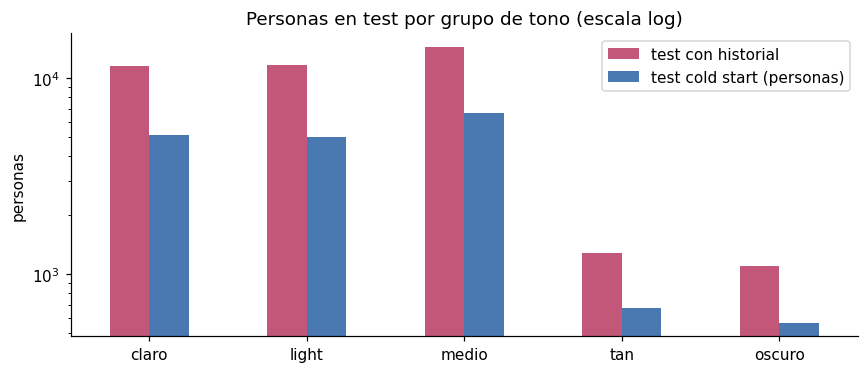

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
c = casos.loc[TONE_GROUP_ORDER, ["test con historial", "test cold start (personas)"]]
c.plot.bar(ax=ax, color=[ROSA, AZUL], logy=True, rot=0)
ax.set(title="Personas en test por grupo de tono (escala log)", xlabel="", ylabel="personas")
plt.tight_layout(); plt.savefig(FIG / "01_test_por_tono.png"); plt.show()

## 6 · Cold start: ¿cuánto hay que adivinar por persona?

En cold start, todos los positivos de la persona son "respuestas correctas". Si alguien tiene un solo positivo, el modelo tiene que acertarle a ese único producto entre 2.351. Es muy difícil, y por eso esperamos números bastante más bajos que con historial.

In [9]:
n_cold = s.test_cold.groupby("author_id").size()
print(f"Positivos por persona en test cold start: mediana {n_cold.median():.0f}, media {n_cold.mean():.2f}")
display(n_cold.clip(upper=5).value_counts().sort_index().rename(index={5: "5+"}).rename("personas").to_frame())

Positivos por persona en test cold start: mediana 1, media 2.04


,personas
1,12962
2,4451
3,1733
4,913
5+,1449


## 7 · Una limitación honesta: el tiempo global

El split es temporal **por persona**: para cada una, test es posterior a su train. Pero **no** es temporal a nivel global. El train de una persona puede incluir reseñas de 2022 mientras el test de otra es de 2019. En la práctica, el modelo "ve el futuro" de otras personas: por ejemplo, sabe qué productos se volvieron populares después.

Es la forma estándar de evaluar en la literatura (*leave-last-out*), pero conviene saberlo y mencionarlo. Un split temporal global (todo antes de una fecha → train, todo después → test) es más realista, pero dejaría muy pocas personas evaluables. Lo dejamos como posible extensión.

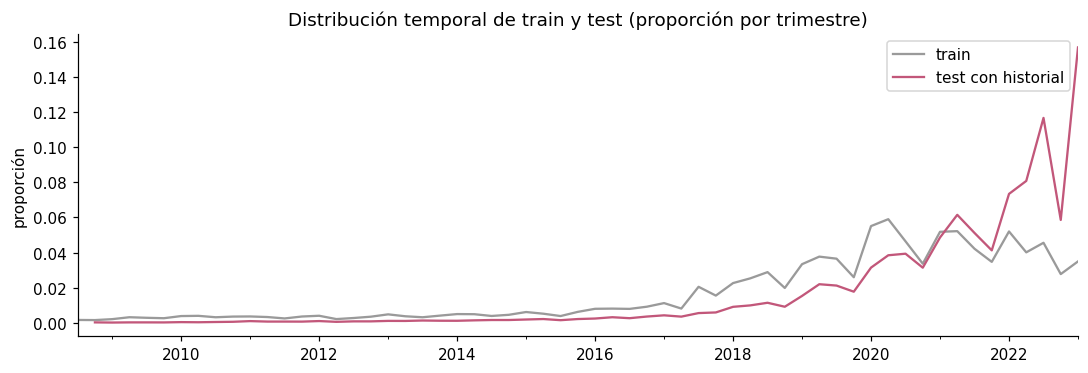

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for df, lab, col in [(s.train, "train", GRIS), (s.test_warm, "test con historial", ROSA)]:
    df.submission_time.dt.to_period("Q").value_counts(normalize=True).sort_index().plot(ax=ax, label=lab, color=col)
ax.set(title="Distribución temporal de train y test (proporción por trimestre)", xlabel="", ylabel="proporción")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "01_tiempo_train_test.png"); plt.show()

## 8 · Productos nuevos en test

¿Hay productos en test que **nunca** aparecen en train? Un modelo que solo usa el ID del producto no los podría recomendar nunca. Uno que usa sus features (marca, categoría, ingredientes) sí. Es uno de los argumentos para la red two-tower.

In [11]:
train_items = set(s.train.product_id)
for df, nombre in [(s.test_warm, "test con historial"), (s.test_cold, "test cold start")]:
    nuevos = ~df.product_id.isin(train_items)
    print(f"{nombre}: {nuevos.mean():.2%} de los casos son productos sin ningún positivo en train ({df.product_id[nuevos].nunique()} productos)")
print(f"Productos del catálogo sin ningún positivo en train: {(~s.items.product_id.isin(train_items)).sum()}")

test con historial: 0.07% de los casos son productos sin ningún positivo en train (9 productos)
test cold start: 0.01% de los casos son productos sin ningún positivo en train (5 productos)
Productos del catálogo sin ningún positivo en train: 26


## 9 · Guardar

Todo queda en `data/processed/` (lo ignora git porque son datos derivados). Los próximos notebooks lo leen con `load_splits()`.

In [12]:
save_splits(s)
for f in sorted((ROOT / "data" / "processed").glob("*.parquet")):
    print(f"{f.name:22s} {f.stat().st_size / 1e6:6.1f} MB")

items.parquet             0.7 MB
test_cold.parquet         0.4 MB
test_warm.parquet         0.6 MB
train.parquet             7.3 MB
users.parquet             5.2 MB
val_cold.parquet          0.4 MB
val_warm.parquet          0.6 MB


## 10 · Conclusiones

### Cómo quedaron los splits

| Split | Qué es | Tamaño |
|---|---|---|
| `train` | positivos para entrenar | 697.572 positivos de 387.149 personas |
| `val_warm` / `test_warm` | 1 producto escondido por persona | 41.509 personas cada uno (las mismas) |
| `val_cold` / `test_cold` | todos los positivos de personas nunca vistas | ~21.500 personas cada uno |

- **Los 7 chequeos pasaron**: no hay personas cold start en train, los productos escondidos no están en el train de la persona, el orden temporal se respeta y todo es reproducible con la semilla 42.
- **Descartar los productos del mismo día cuesta poco**: 3,1% de los positivos. Es un precio bajo por evitar la fuga de información dentro de una sesión.

### Lo que esto anticipa para los modelos

- **Exigir 3 días distintos redujo el set evaluable a la mitad** de lo estimado en el notebook 00 (41,5 mil personas en lugar de 83 mil), porque muchas personas escriben varias reseñas el mismo día. Igual alcanza de sobra.
- **El grupo de tono *oscuro* tiene ~1.100 casos en test con historial y ~570 personas en cold start.** El error estándar es de ±1,2 y ±1,7 puntos de recall. Alcanza para detectar brechas de varios puntos, pero no diferencias chiquitas. Con los tonos sin agrupar no hubiera sido posible.
- **El cold start va a ser difícil**: el 60% de las personas de test cold start tiene **un solo** positivo para adivinar entre 2.351 productos. Hay que esperar números mucho más bajos que con historial, y por eso los comparamos siempre contra el baseline de popularidad, no en abstracto.
- **Casi no hay productos "nuevos" en test** (0,07%): un modelo que solo usa el ID del producto no queda en desventaja por eso. La ventaja de usar features de producto (ingredientes, marca) va a tener que verse en otro lado, como en los productos con pocas reseñas.

### Cosas a tener en cuenta

- **Tiempo global** (sección 7): el modelo puede "ver el futuro" de otras personas. Es la forma estándar de evaluar, pero lo mencionamos como limitación.
- **Mini vs. tamaño normal**: son productos distintos en el catálogo (172 minis; 129 con su versión normal). En el ejemplo de la sección 2, el limpiador mini fue a test y el tamaño normal se descartó. El caso en que el modelo "acierta" porque la persona ya tenía el producto en otro tamaño es solo el 0,02% de test (con coincidencia exacta de nombre), así que no hace falta corregirlo. Si en el análisis de errores vemos que el modelo recomienda mucho minis, lo revisamos.
- **El grupo *desconocido*** (personas sin tono declarado) entra en el entrenamiento y en la métrica general, pero no en el análisis por tono.